# Starting with loading the file

## 1. Loading & data quality

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/paysim_raw.csv")
df

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.00,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.00,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...
6362615,743,CASH_OUT,339682.13,C786484425,339682.13,0.00,C776919290,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,C1529008245,6311409.28,0.00,C1881841831,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,C1162922333,6311409.28,0.00,C1365125890,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,C1685995037,850002.52,0.00,C2080388513,0.00,0.00,1,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB


In [3]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [4]:
df.shape

(6362620, 11)

In [5]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [6]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


**No missing values, no duplicate values. 6.36M rows * 11 columns , Data is clean**

## 2. Fraud by transaction type

In [9]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [10]:
df.groupby('type')['isFraud'].mean()

type
CASH_IN     0.000000
CASH_OUT    0.001840
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.007688
Name: isFraud, dtype: float64

In [11]:
df.groupby('type')['isFraud'].sum()

type
CASH_IN        0
CASH_OUT    4116
DEBIT          0
PAYMENT        0
TRANSFER    4097
Name: isFraud, dtype: int64

**Cash_out has 4116 fruads and transfer type has 4097 frauds, almost equal , diff is only 19**

In [12]:
df.groupby('type')['isFraud'].value_counts()

type      isFraud
CASH_IN   0          1399284
CASH_OUT  0          2233384
          1             4116
DEBIT     0            41432
PAYMENT   0          2151495
TRANSFER  0           528812
          1             4097
Name: count, dtype: int64

### only cash_out and Trasfer contains the fraud, others (cash_in, debit, payment) don't contains any fraud

In [13]:
df_fd = df[df['type'].isin(['TRANSFER','CASH_OUT'])].copy()
df_fd['type'].value_counts()

type
CASH_OUT    2237500
TRANSFER     532909
Name: count, dtype: int64

In [14]:
df_fd.shape

(2770409, 11)

In [15]:
df_fd['isFraud'].mean()*100

np.float64(0.2964544224336551)

### about 3 frauds in per 1000 transaction in the cash_out and transfer

In [16]:
pd.crosstab(df_fd['isFraud'], df_fd['isFlaggedFraud'])

isFlaggedFraud,0,1
isFraud,,
0,2762196,0
1,8197,16


**ifFlaggedFraud just caught 16 out of 8213 fraud and had 0 false alarm , it doen't help us at all. we can drop this.**

## 3. Amount analysis

In [17]:
df_fd.groupby('type')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
CASH_OUT,2237500.0,176273.964346,1.753297e+05,0.0,72669.65,147072.185,246539.4775,10000000.00
TRANSFER,532909.0,910647.009645,1.879574e+06,2.6,215905.35,486308.390,974958.0000,92445516.64


**Trasfer median is much larger then cash_out, 486K>147K**

In [18]:
df_fd.groupby('isFraud')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,2762196.0,3.141155e+05,8.771441e+05,0.01,82908.2325,171034.46,305994.185,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.3300,441423.44,1517771.480,10000000.00


### Median fraud amount is 441k, median non-fraud is 171k. A typical fraud is about 2.6x larger than a normal transaction. 

In [19]:
df_fd = df_fd.drop(columns = 'isFlaggedFraud')

In [20]:
df_fd.groupby('isFraud')['amount'].skew()

isFraud
0    22.582054
1     2.385149
Name: amount, dtype: float64

both are Right skew, but non Fraud is emtremly skewed.

In [21]:
fraud = df_fd[df_fd['isFraud'] == 1]
(fraud['amount'] == 10_000_000).sum(), (fraud['amount'] == 0).sum()

(np.int64(287), np.int64(16))

- **287 of 8213 frauds (~3.5%) are exactly 10M.** Real transactions e rearly round number thake, so this looks like a **transaction limit**. When a victim has more than 10M, the fraudster probably moves it in several 10M chunks.
- **16 frauds of 0 amount** don't make sense as real theft. These are probably data errors or simulation artifacts. We don't delete them yet; just note them.

## 4. Balance & amount features

In [22]:
df_fd['empties_amount'] = df_fd['amount'] == df_fd['oldbalanceOrg']

df_fd.groupby('isFraud')['empties_amount'].mean()

isFraud
0    0.000000
1    0.978205
Name: empties_amount, dtype: float64

**it's suspiciously clean. As PaySim is simulated data, and real fraud data is never like this. this is much more simulated synthetic data. 97.8% of frauds empty the sender's account vs 0% of non-fraud. Strongest signal so far.** 

In [23]:
# frauds that do NOT empty the sender's account
frauds = df_fd[df_fd['isFraud'] == 1]
not_empty = frauds[frauds['empties_amount'] == False]
print("Frauds not emptying the account:", len(not_empty))

# how many of them are exactly 10M?
is_10m = not_empty['amount'] == 10_000_000
print("Exactly 10M:", is_10m.sum(), f"({is_10m.mean():.0%})")

# do those 10M accounts hold more than 10M?
print("Balance above 10M:", (not_empty.loc[is_10m, 'oldbalanceOrg'] > 10_000_000).sum())

Frauds not emptying the account: 179
Exactly 10M: 145 (81%)
Balance above 10M: 145


179 frauds don’t empty the account. 145 of them (81%) are exactly 10M from accounts holding more than 10M → a per-transaction limit; the fraudster can’t empty the account in one go. This confirms my guess in section 3.

In [24]:
df_fd['is_whole'] = df_fd['amount'] % 1 == 0
df_fd.groupby('isFraud')['is_whole'].mean()

isFraud
0    0.011112
1    0.061001
Name: is_whole, dtype: float64

In [25]:
rest = df_fd[(df_fd['amount'] != 10_000_000) & (df_fd['amount'] != 0)]
rest.groupby('isFraud')['is_whole'].mean()

isFraud
0    0.010066
1    0.025032
Name: is_whole, dtype: float64

**Without 10M and 0 cases: 2.5% of frauds are whole numbers vs 1.0% of non-fraud. Most whole-number frauds were the 10M and 0 cases.**

In [26]:
ans = rest.groupby(['isFraud','is_whole'])['amount'].count()
print(ans)

isFraud  is_whole
0        False       2731502
         True          27774
1        False          7712
         True            198
Name: amount, dtype: int64


In [27]:
df_fd['dest_zero'] = (df_fd['oldbalanceDest'] == 0) & (df_fd['newbalanceDest'] == 0)
df_fd.groupby('isFraud')['dest_zero'].mean()

isFraud
0    0.000618
1    0.496286
Name: dest_zero, dtype: float64

In [28]:
fraud = df_fd[df_fd['isFraud'] == 1]
fraud.groupby('type')['dest_zero'].mean()

type
CASH_OUT    0.001944
TRANSFER    0.992922
Name: dest_zero, dtype: float64

In [29]:
df_fd.groupby(['type', 'isFraud'])['dest_zero'].mean()

type      isFraud
CASH_OUT  0          0.000716
          1          0.001944
TRANSFER  0          0.000200
          1          0.992922
Name: dest_zero, dtype: float64

ekhane theke ekta jinis bujhlam je transfer type er jonne fraud hoy thle setar dest_zero mean(old = newbalance =0) hbe 99.3% times. non-fraud TRANSFER only 0.02%

**We found that**
- about 16 fraud has amount 0
- other 4000 fraud in trasfer has oldbalancedest = newbalancedest = 0, but the amount wasn't zero
- so sender sends some amount but the receiver don't revices this.

In [30]:
ft = df_fd[(df_fd['isFraud'] == 1) & (df_fd['type'] == 'TRANSFER') & (df_fd['dest_zero'])]
(ft['amount'] == 0).sum(), ft['amount'].describe()

(np.int64(0),
 count    4.068000e+03
 mean     1.486505e+06
 std      2.421847e+06
 min      6.380000e+01
 25%      1.284244e+05
 50%      4.458694e+05
 75%      1.539528e+06
 max      1.000000e+07
 Name: amount, dtype: float64)

In [31]:
ft['empties_amount'].mean()*100

np.float64(96.36184857423795)

**Fraud TRANSFERs with dest_zero: 96.36% empty the sender's account.**

## 5. Tracing accounts & limitations

In [32]:
transfer_dest = set(fraud[fraud['type'] == 'TRANSFER']['nameDest'])
cashout_orig = set(fraud[fraud['type'] == 'CASH_OUT']['nameOrig'])
len(transfer_dest & cashout_orig)

0

ekhane theke amra bujte partesi je ekta fraud je account e ekbar transaction korse kintu seta receive hoy nai, sei account e se abr kokkhon o cashout kore nai.

**Update (section 16): the chain cannot be traced by account names (0 matches), but 99.5% of fraud TRANSFERs have a fraud CASH_OUT at the same step and same amount (legit: 0.01%). So fraud is a two-step TRANSFER → CASH_OUT pattern, linked by step + amount, not by account. H7 = supported.**

In [33]:
df['nameOrig'].nunique(), df['nameDest'].nunique(), len(df)

(6353307, 2722362, 6362620)

jehetu ekhane proty ta sender transaction pray unique. tai ekhane theke amra trace korte parbo na money koi theke koi jacche. eta ekta limitation.

sender name column just ekta id , eta amdr kono kaj e asbe na. tai amra model train er age bad diye dite pari. karon je ekbar transaction korse tar kono history nai. so sender has no history.

## 5b. Time analysis

In [34]:
df_fd['hour'] = df_fd['step'] % 24
df_fd.groupby('hour')['isFraud'].mean()

hour
0     0.016471
1     0.059617
2     0.193548
3     0.417949
4     0.535156
5     0.579114
6     0.396018
7     0.129032
8     0.035721
9     0.002841
10    0.002005
11    0.001634
12    0.001551
13    0.001618
14    0.001771
15    0.001813
16    0.001717
17    0.001741
18    0.001267
19    0.001140
20    0.001423
21    0.003816
22    0.005739
23    0.008492
Name: isFraud, dtype: float64

**Hour 5 has the highest fraud rate: 57.9%. Hours 3-6 are all above 40%. Day hours (10-20) only ~0.15%.**

In [35]:
df_fd.groupby('hour')['isFraud'].agg(['sum', 'count','mean'])

,sum,count,mean
hour,,,
0,300,18214,0.016471
1,358,6005,0.059617
2,372,1922,0.193548
3,326,780,0.417949
4,274,512,0.535156
5,366,632,0.579114
6,358,904,0.396018
7,328,2542,0.129032
8,368,10302,0.035721


From here, Fraud count is roughly the same every hour (~350). Total transactions drop a lot at night (e.g. 632 at hour 5 vs 213,906 at hour 13), so the fraud RATE is high at night.

## 6. Preprocessing

In [36]:
model_df = df_fd.drop(columns=['nameOrig', 'nameDest', 'step'])
model_df['type'] = (model_df['type'] == 'TRANSFER').astype(int)

bool_cols = ['empties_amount', 'is_whole', 'dest_zero']
model_df[bool_cols] = model_df[bool_cols].astype(int)

model_df.info()

<class 'pandas.DataFrame'>
Index: 2770409 entries, 2 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   type            int64  
 1   amount          float64
 2   oldbalanceOrg   float64
 3   newbalanceOrig  float64
 4   oldbalanceDest  float64
 5   newbalanceDest  float64
 6   isFraud         int64  
 7   empties_amount  int64  
 8   is_whole        int64  
 9   dest_zero       int64  
 10  hour            int64  
dtypes: float64(5), int64(6)
memory usage: 253.6 MB


In [37]:
model_df

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,empties_amount,is_whole,dest_zero,hour
2,1,181.00,181.00,0.0,0.00,0.00,1,1,1,1,1
3,0,181.00,181.00,0.0,21182.00,0.00,1,1,1,0,1
15,0,229133.94,15325.00,0.0,5083.00,51513.44,0,0,0,0,1
19,1,215310.30,705.00,0.0,22425.00,0.00,0,0,0,0,1
24,1,311685.89,10835.00,0.0,6267.00,2719172.89,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
6362615,0,339682.13,339682.13,0.0,0.00,339682.13,1,1,0,0,23
6362616,1,6311409.28,6311409.28,0.0,0.00,0.00,1,1,0,1,23
6362617,0,6311409.28,6311409.28,0.0,68488.84,6379898.11,1,1,0,0,23
6362618,1,850002.52,850002.52,0.0,0.00,0.00,1,1,0,1,23


**Dropped nameOrig, nameDest, step. type: 1 = TRANSFER, 0 = CASH_OUT. True/False → 1/0. All columns are numbers now.**

In [38]:
from sklearn.model_selection import train_test_split

X = model_df.drop(columns='isFraud')
y = model_df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train.shape, X_test.shape, y_train.mean(), y_test.mean()

((2216327, 10),
 (554082, 10),
 np.float64(0.0029643640130720783),
 np.float64(0.002965265069069199))

**80/20 stratified split. Train 2.2M rows, test 554k rows. Both have 0.296% fraud rate.**

## 7. Baseline model

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    552439
           1     0.9994    0.9957    0.9976      1643

    accuracy                         1.0000    554082
   macro avg     0.9997    0.9979    0.9988    554082
weighted avg     1.0000    1.0000    1.0000    554082



**Logistic Regression (baseline): fraud precision 0.9994, recall 0.9957, F1 0.9976 on 1,643 test frauds.**

In [40]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[552438,      1],
       [     7,   1636]])

**1 false alarm, 7 frauds missed, out of 554k test rows. Too good for real fraud data.**

In [41]:
X_train['type'].value_counts()

type
0    1790164
1     426163
Name: count, dtype: int64

In [42]:
y_train

5359676    0
5539126    0
2188719    0
2594313    0
421860     0
          ..
1139492    0
4718290    0
2587195    0
5651064    0
3048392    0
Name: isFraud, Length: 2216327, dtype: int64

## 8. Ablation study

In [43]:
from sklearn.metrics import precision_score, recall_score

def run(drop_cols):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(X_train.drop(columns=drop_cols), y_train)
    pred = model.predict(X_test.drop(columns=drop_cols))
    return precision_score(y_test, pred), recall_score(y_test, pred)

In [44]:
run(['empties_amount', 'dest_zero', 'is_whole'])

(0.8873072360616845, 0.45526475958612295)

**Without empties_amount, dest_zero, is_whole: precision 0.887, recall 0.455.**
**Recall dropped from 0.996 to 0.455. The model depends mostly on these features.**

In [45]:
print('no empties_amount:', run(['empties_amount']))
print('no dest_zero:     ', run(['dest_zero']))
print('no is_whole:      ', run(['is_whole']))

no empties_amount: (0.8927392739273927, 0.6585514303104077)
no dest_zero:      (0.9993891264508247, 0.995739500912964)
no is_whole:       (0.9993891264508247, 0.995739500912964)


1. amra empties_amount column bad dile eta amdr recall(joto gula real fruad tar moddhe model koto gula fruad bolse) kome jay 34 points.

2. is_whole column bad dileo eta tmn kono effect fele na. eta drop kore dileo problem nai.

3. dest_zero dekhe mone hote pare je eta useless but eta uselsss na. etar sathe baki 2 ta column i bad diye dile tokhon recall er value 0.455 e neme ase. **dest_zero and empties_amount carry mostly the same information (redundancy, 96.36%).**

## 9. Tree model (HistGradientBoosting)

In [46]:
from sklearn.ensemble import HistGradientBoostingClassifier

drop = ['empties_amount', 'dest_zero', 'is_whole']
hgb = HistGradientBoostingClassifier(random_state=42)
hgb.fit(X_train.drop(columns=drop), y_train)
pred = hgb.predict(X_test.drop(columns=drop))
precision_score(y_test, pred), recall_score(y_test, pred)

(0.7820131030375224, 0.7991479001825929)

ekhane theke amra dekhte partesi , tree oi tinta column (empties_amount, is_whole,dest_zero) badei valo result disse. precision 0.782 and recall 0.799.

In [47]:
hgb_all = HistGradientBoostingClassifier(random_state=42)
hgb_all.fit(X_train, y_train)
pred = hgb_all.predict(X_test)
precision_score(y_test, pred), recall_score(y_test, pred)

(0.9951367781155015, 0.9963481436396835)

**HGB with all features: precision 0.9951, recall 0.9963.**
**vs LR baseline: 1 more fraud caught (6 missed vs 7), but 8 false alarms vs 1. F1 0.9957 vs 0.9976, LR slightly better.**

## 10. Time-based split

In [48]:
step = df_fd['step']
cutoff = step.quantile(0.8)

train_mask = step <= cutoff
X_train_t, X_test_t = X[train_mask], X[~train_mask]
y_train_t, y_test_t = y[train_mask], y[~train_mask]

cutoff, X_train_t.shape, X_test_t.shape, y_train_t.mean(), y_test_t.mean()

(np.float64(354.0),
 (2217905, 10),
 (552504, 10),
 np.float64(0.0017832143396583713),
 np.float64(0.007706731534975312))

**Time split at step 354. Train = steps 1-354 (2.2M rows), test = steps 355-743 (552k rows).**
**Test covers more than half the time but only 20% of rows, so later steps have far fewer transactions.**
**Fraud rate: train 0.18%, test 0.77% (~4x higher). Fraud stays constant over time, normal transactions drop.**

In [49]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

def evaluate(model):
    model.fit(X_train_t, y_train_t)
    pred = model.predict(X_test_t)
    return (round(precision_score(y_test_t, pred), 4),
            round(recall_score(y_test_t, pred), 4),
            round(f1_score(y_test_t, pred), 4))

print('LR :', evaluate(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))))
print('HGB:', evaluate(HistGradientBoostingClassifier(random_state=42)))
print('RF :', evaluate(RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)))

LR : (1.0, 0.9986, 0.9993)
HGB: (0.9959, 0.9032, 0.9473)
RF : (1.0, 0.9998, 0.9999)


**Time split (4,258 test frauds): RF F1 0.9999 (~1 missed), LR F1 0.9993 (~6 missed), HGB F1 0.9473 (~412 missed).**
**RF and LR: precision 1.0, 0 false alarms. RF best, but LR almost the same and much simpler.**
**HGB recall dropped from 0.996 (random split) to 0.903. Only model that got worse on future data. Reason not known yet.**

In [50]:
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
print(evaluate(rf))
8
pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

(1.0, 0.9998, 0.9999)


empties_amount    0.754386
dest_zero         0.084709
oldbalanceOrg     0.046904
type              0.034930
amount            0.029237
newbalanceDest    0.017559
newbalanceOrig    0.013023
oldbalanceDest    0.010883
hour              0.007158
is_whole          0.001210
dtype: float64

**RF importance: empties_amount 0.75, dest_zero 0.08, then balances. hour only 0.007, is_whole 0.001.**
**hour was strong in EDA but adds little here, because empties_amount already finds most frauds (redundancy).**

## 11. Random Forest on the random split

In [51]:
rf_r = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf_r.fit(X_train, y_train)
pred = rf_r.predict(X_test)
precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred), confusion_matrix(y_test, pred)

(1.0,
 0.9963481436396835,
 0.9981707317073171,
 array([[552439,      0],
        [     6,   1637]]))

**RF random split: precision 1.0, recall 0.9963, F1 0.9982. 0 false alarms, 6 missed.**
**Best on random split too (LR 0.9976, HGB 0.9957).**

## 12. Why did HGB drop on the time split?

In [52]:
hgb_t = HistGradientBoostingClassifier(random_state=42)
hgb_t.fit(X_train_t, y_train_t)
proba = hgb_t.predict_proba(X_test_t)[:, 1]

is_fraud = (y_test_t == 1).values
fraud_t = X_test_t[is_fraud].copy()
fraud_t['proba'] = proba[is_fraud]
fraud_t['missed'] = fraud_t['proba'] < 0.5

fraud_t.groupby('missed').agg(count=('amount', 'size'), amount_median=('amount', 'median'),
                              empties_share=('empties_amount', 'mean'), proba_mean=('proba', 'mean'))

,count,amount_median,empties_share,proba_mean
missed,,,,
False,3846,372703.48,1.000000,1.000000e+00
True,412,9725837.08,0.745146,7.219903e-08


**412 frauds missed. Their probability is 0.0, so HGB is 100% sure they are not fraud. Lowering the threshold does not help.**
**Missed frauds are very large: median amount ~9.7M vs ~373k for caught frauds.**
**74.5% of missed frauds have empties_amount = 1, but no non-fraud ever has empties_amount = 1. HGB still missed them.**
**Misses are spread evenly over steps 355-743, so it is not slow drift over time.**

In [53]:
print('default     :', evaluate(HistGradientBoostingClassifier(random_state=42)))
print('l2 = 1      :', evaluate(HistGradientBoostingClassifier(random_state=42, l2_regularization=1.0)))
print('max_depth=3 :', evaluate(HistGradientBoostingClassifier(random_state=42, max_depth=3)))

default     : (0.9959, 0.9032, 0.9473)
l2 = 1      : (1.0, 0.9998, 0.9999)
max_depth=3 : (1.0, 0.9998, 0.9999)


**With regularization (l2_regularization=1 or max_depth=3): F1 0.9999, same as RF.**
**Without early stopping (100 trees), HGB collapses: recall 0.055.**
**Reason: data is almost perfectly separable, so default HGB becomes overconfident and unstable. Regularization fixes it.**
**The drop was a model-settings problem, not a time-split problem.**

## 13. Simple rule baseline

In [54]:
def rule_scores(X_part, y_part):
    pred = X_part['empties_amount']
    return (round(precision_score(y_part, pred), 4),
            round(recall_score(y_part, pred), 4),
            round(f1_score(y_part, pred), 4))

print('Rule, random split:', rule_scores(X_test, y_test))
print('Rule, time split :', rule_scores(X_test_t, y_test_t))

Rule, random split: (1.0, 0.9781, 0.9889)
Rule, time split : (1.0, 0.9753, 0.9875)


**Rule (empties_amount = 1 → fraud), no training: precision 1.0 on both splits, 0 false alarms.**
**Random split: recall 0.9781, F1 0.9889 (~36 missed). Time split: recall 0.9753, F1 0.9875 (~105 missed).**
**RF catches ~30 more frauds (random) and ~104 more (time). ML only adds ~2 recall points over the rule.**
**Those extra frauds are the ones that don't empty the account (10M chunks, 0 amounts).**

In [55]:
X_train.shape

(2216327, 10)

In [56]:
X_test.shape

(554082, 10)

## 14. Figures

In [57]:
import matplotlib.pyplot as plt
import os

os.makedirs('../figures', exist_ok=True)

plt.rcParams.update({
    'font.family': 'Arial', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.5, 'axes.axisbelow': True,
    'axes.edgecolor': '#898781', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'savefig.dpi': 600, 'savefig.bbox': 'tight',
})
LEGIT, FRAUD = '#2a78d6', '#eb6834'

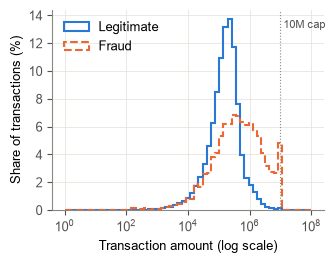

In [58]:
legit = df_fd.loc[df_fd['isFraud'] == 0, 'amount']
fraud = df_fd.loc[df_fd['isFraud'] == 1, 'amount']
legit, fraud = legit[legit > 0], fraud[fraud > 0]
bins = np.logspace(0, 8, 60)

fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.hist(legit, bins=bins, weights=np.full(len(legit), 100 / len(legit)),
        histtype='step', linewidth=1.5, color=LEGIT, label='Legitimate')
ax.hist(fraud, bins=bins, weights=np.full(len(fraud), 100 / len(fraud)),
        histtype='step', linewidth=1.5, linestyle='--', color=FRAUD, label='Fraud')
ax.axvline(1e7, color='#898781', linewidth=0.8, linestyle=':')
ax.text(1e7, ax.get_ylim()[1] * 0.95, ' 10M cap', color='#52514e', fontsize=8, va='top')
ax.set_xscale('log')
ax.set_xlabel('Transaction amount (log scale)')
ax.set_ylabel('Share of transactions (%)')
ax.legend(frameon=False, loc='upper left')

fig.savefig('../figures/fig2_amount_distribution.pdf')
fig.savefig('../figures/fig2_amount_distribution.png')
plt.show()

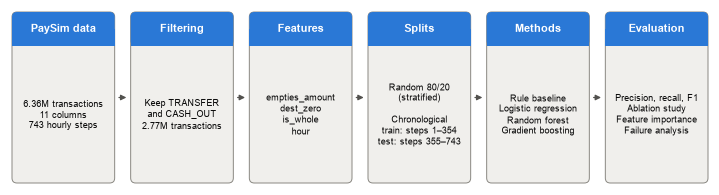

In [59]:
from matplotlib.patches import FancyBboxPatch, Rectangle

steps = [
    ('PaySim data', '6.36M transactions\n11 columns\n743 hourly steps'),
    ('Filtering', 'Keep TRANSFER\nand CASH_OUT\n2.77M transactions'),
    ('Features', 'empties_amount\ndest_zero\nis_whole\nhour'),
    ('Splits', 'Random 80/20\n(stratified)\n\nChronological\ntrain: steps 1–354\ntest: steps 355–743'),
    ('Methods', 'Rule baseline\nLogistic regression\nRandom forest\nGradient boosting'),
    ('Evaluation', 'Precision, recall, F1\nAblation study\nFeature importance\nFailure analysis'),
]

W, H = 7.0, 1.75
fig = plt.figure(figsize=(W, H))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.axis('off')

n, gap = len(steps), 0.16
box_w = (W - 0.04 - gap * (n - 1)) / n
y0, h, head = 0.02, H - 0.04, 0.34

for k, (title, detail) in enumerate(steps):
    x = 0.02 + k * (box_w + gap)
    ax.add_patch(FancyBboxPatch((x, y0), box_w, h, boxstyle='round,pad=0,rounding_size=0.05',
                                facecolor='#f0efec', edgecolor='#898781', linewidth=0.7))
    ax.add_patch(FancyBboxPatch((x, y0 + h - head), box_w, head, boxstyle='round,pad=0,rounding_size=0.05',
                                facecolor=LEGIT, edgecolor='none'))
    ax.add_patch(Rectangle((x, y0 + h - head), box_w, head / 2, facecolor=LEGIT, edgecolor='none'))
    ax.text(x + box_w / 2, y0 + h - head / 2, title, ha='center', va='center',
            color='white', fontsize=8, fontweight='bold')
    ax.text(x + box_w / 2, y0 + (h - head) / 2, detail, ha='center', va='center',
            color='#0b0b0b', fontsize=6.5, linespacing=1.3)
    if k < n - 1:
        ax.annotate('', xy=(x + box_w + gap - 0.015, y0 + h / 2), xytext=(x + box_w + 0.015, y0 + h / 2),
                    arrowprops=dict(arrowstyle='-|>', color='#52514e', linewidth=0.9, mutation_scale=8))

fig.savefig('../archive/fig1_pipeline.pdf')
fig.savefig('../archive/fig1_pipeline.png')
plt.show()

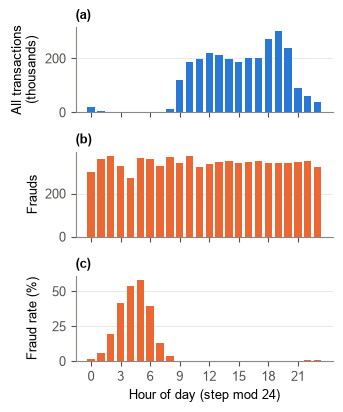

In [60]:
by_hour = df_fd.groupby('hour')['isFraud'].agg(total='count', frauds='sum')
by_hour['rate'] = by_hour['frauds'] / by_hour['total'] * 100

panels = [
    (by_hour['total'] / 1000, LEGIT, 'All transactions\n(thousands)'),
    (by_hour['frauds'], FRAUD, 'Frauds'),
    (by_hour['rate'], FRAUD, 'Fraud rate (%)'),
]

fig, axes = plt.subplots(3, 1, figsize=(3.5, 4.2), sharex=True)
for ax, letter, (values, color, label) in zip(axes, 'abc', panels):
    ax.bar(by_hour.index, values, color=color, width=0.75)
    ax.set_ylabel(label)
    ax.set_title(f'({letter})', loc='left', fontsize=9, fontweight='bold')
    ax.grid(axis='x', visible=False)

axes[-1].set_xlabel('Hour of day (step mod 24)')
axes[-1].set_xticks(range(0, 24, 3))
fig.align_ylabels(axes)
fig.tight_layout()

fig.savefig('../figures/fig3_hourly_pattern.pdf')
fig.savefig('../figures/fig3_hourly_pattern.png')
plt.show()

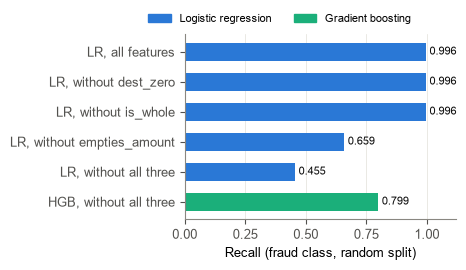

In [61]:
from matplotlib.patches import Patch

HGB_COLOR = '#1baf7a'

ablation = [
    ('LR, all features', 0.9957, LEGIT),
    ('LR, without dest_zero', 0.9957, LEGIT),
    ('LR, without is_whole', 0.9957, LEGIT),
    ('LR, without empties_amount', 0.6586, LEGIT),
    ('LR, without all three', 0.4553, LEGIT),
    ('HGB, without all three', 0.7991, HGB_COLOR),
]
labels = [a[0] for a in ablation]
recalls = [a[1] for a in ablation]
colors = [a[2] for a in ablation]

fig, ax = plt.subplots(figsize=(3.5, 2.4))
ypos = range(len(ablation))
ax.barh(ypos, recalls, color=colors, height=0.6)
for yi, r in zip(ypos, recalls):
    ax.text(r + 0.015, yi, f'{r:.3f}', va='center', fontsize=8, color='#0b0b0b')

ax.set_yticks(list(ypos), labels)
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel('Recall (fraud class, random split)')
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=LEGIT, label='Logistic regression'),
                   Patch(color=HGB_COLOR, label='Gradient boosting')],
          frameon=False, loc='lower center', bbox_to_anchor=(0.35, 1.0), ncol=2, fontsize=8)

fig.savefig('../figures/fig5_ablation.pdf')
fig.savefig('../figures/fig5_ablation.png')
plt.show()

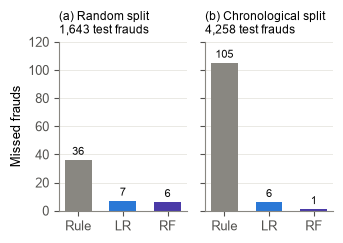

In [62]:
RULE_COLOR, RF_COLOR = '#898781', '#4a3aa7'

methods = ['Rule', 'LR', 'RF']
colors = [RULE_COLOR, LEGIT, RF_COLOR]
splits = [
    ('(a) Random split\n1,643 test frauds', [36, 7, 6]),
    ('(b) Chronological split\n4,258 test frauds', [105, 6, 1]),
]

fig, axes = plt.subplots(1, 2, figsize=(3.5, 2.5), sharey=True)
for ax, (title, missed) in zip(axes, splits):
    ax.bar(methods, missed, color=colors, width=0.6)
    for x, m in enumerate(missed):
        ax.text(x, m + 2, str(m), ha='center', va='bottom', fontsize=8, color='#0b0b0b')
    ax.set_title(title, loc='left', fontsize=8.5)
    ax.grid(axis='x', visible=False)

axes[0].set_ylabel('Missed frauds')
axes[0].set_ylim(0, 120)
fig.tight_layout()

fig.savefig('../figures/fig6_rule_vs_ml.pdf')
fig.savefig('../figures/fig6_rule_vs_ml.png')
plt.show()

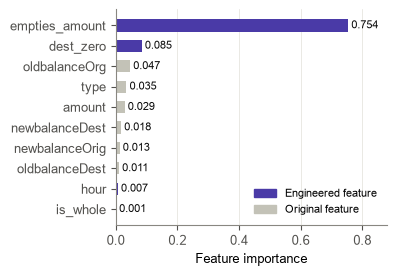

In [63]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

ORIGINAL_COLOR = '#c3c2b7'
engineered = ['empties_amount', 'dest_zero', 'is_whole', 'hour']
colors = [RF_COLOR if f in engineered else ORIGINAL_COLOR for f in importance.index]

fig, ax = plt.subplots(figsize=(3.5, 2.8))
ypos = range(len(importance))
ax.barh(ypos, importance.values, color=colors, height=0.6)
for yi, v in zip(ypos, importance.values):
    ax.text(v + 0.01, yi, f'{v:.3f}', va='center', fontsize=8, color='#0b0b0b')

ax.set_yticks(list(ypos), importance.index)
ax.invert_yaxis()
ax.set_xlim(0, 0.88)
ax.set_xlabel('Feature importance')
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=RF_COLOR, label='Engineered feature'),
                   Patch(color=ORIGINAL_COLOR, label='Original feature')],
          frameon=False, loc='lower right', fontsize=8)

fig.savefig('../figures/fig7_feature_importance.pdf')
fig.savefig('../figures/fig7_feature_importance.png')
plt.show()

## 15. Expanding-window evaluation

In [64]:
y = model_df['isFraud']
cutoffs = [200, 300, 400, 500, 600]
horizon = 100
step = df_fd['step']

fold_info = []
for c in cutoffs:
    train_mask = step <= c
    test_mask = (step > c) & (step <= c + horizon)
    fold_info.append({'cutoff': c, 'test_steps': f'{c + 1}-{c + horizon}',
                      'train_rows': train_mask.sum(), 'test_rows': test_mask.sum(),
                      'train_frauds': y[train_mask].sum(), 'test_frauds': y[test_mask].sum()})
pd.DataFrame(fold_info)

,cutoff,test_steps,train_rows,test_rows,train_frauds,test_frauds
0,200,201-300,1045328,735216,2254,1147
1,300,301-400,1780544,748992,3401,1076
2,400,401-500,2529536,116243,4477,1084
3,500,501-600,2645779,81080,5561,1052
4,600,601-700,2726859,38333,6613,1110


**5 folds: train up to the cut-off, test on the next 100 steps. Every fold has more train frauds than test frauds (~1,050–1,150 test frauds each). Test fraud rate rises from 0.16% to 2.9% in later folds.**

In [65]:
from sklearn.metrics import confusion_matrix

def fold_scores(y_true, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {'precision': precision_score(y_true, pred), 'recall': recall_score(y_true, pred),
            'f1': f1_score(y_true, pred), 'false_alarms': fp, 'missed': fn}

models = {
    'LR': lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'HGB default': lambda: HistGradientBoostingClassifier(random_state=42),
    'HGB l2=1': lambda: HistGradientBoostingClassifier(random_state=42, l2_regularization=1.0),
    'RF': lambda: RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

results = []
for c in cutoffs:
    train_mask = step <= c
    test_mask = (step > c) & (step <= c + horizon)
    X_tr, y_tr = X[train_mask], y[train_mask]
    X_te, y_te = X[test_mask], y[test_mask]

    results.append({'cutoff': c, 'method': 'Rule', **fold_scores(y_te, X_te['empties_amount'])})
    for name, make_model in models.items():
        model = make_model()
        model.fit(X_tr, y_tr)
        results.append({'cutoff': c, 'method': name, **fold_scores(y_te, model.predict(X_te))})
    print('done cutoff', c)

results_df = pd.DataFrame(results)
results_df.to_csv('../results/expanding_window_results.csv', index=False)
results_df

done cutoff 200
done cutoff 300
done cutoff 400
done cutoff 500
done cutoff 600


,cutoff,method,precision,recall,f1,false_alarms,missed
0,200,Rule,1.000000,0.979076,0.989427,0,24
1,200,LR,0.983663,0.997384,0.990476,19,3
2,200,HGB default,0.998255,0.997384,0.997819,2,3
3,200,HGB l2=1,1.000000,0.997384,0.998691,0,3
4,200,RF,1.000000,0.997384,0.998691,0,3
5,300,Rule,1.000000,0.981413,0.990619,0,20
6,300,LR,1.000000,1.000000,1.000000,0,0
7,300,HGB default,0.974615,0.999071,0.986691,28,1
8,300,HGB l2=1,1.000000,1.000000,1.000000,0,0
9,300,RF,1.000000,1.000000,1.000000,0,0


In [66]:
results_df.groupby('method')[['precision', 'recall', 'f1', 'missed']].agg(['mean', 'std']).round(4)

precision          recall              f1         missed        
                 mean     std    mean     std    mean     std   mean     std
method                                                                      
HGB default    0.9936  0.0107  0.9991  0.0011  0.9963  0.0055    1.0  1.2247
HGB l2=1       1.0000  0.0000  0.9993  0.0011  0.9996  0.0006    0.8  1.3038
LR             0.9967  0.0073  0.9987  0.0012  0.9977  0.0041    1.4  1.3416
RF             1.0000  0.0000  0.9993  0.0011  0.9996  0.0006    0.8  1.3038
Rule           1.0000  0.0000  0.9790  0.0054  0.9894  0.0028   23.0  6.2450

**Mean F1 over 5 folds: RF 0.9996, HGB l2=1 0.9996, LR 0.9977, HGB default 0.9963, Rule 0.9894.**
**Results are stable over time (small std). Rule still misses ~23 frauds per fold, ML ~1.**
**Default HGB did not repeat the big 412-miss failure here; its problem shows as extra false alarms (28 at cut-off 300). So the 412-miss failure was specific to the step-354 cut.**

## 16. H7 re-check and pair-leakage test

**Fraud pairs by step + amount**

In [67]:
fraud = df_fd[df_fd['isFraud'] == 1]
ft = fraud[fraud['type'] == 'TRANSFER']
fc = fraud[fraud['type'] == 'CASH_OUT']

cashout_keys = set(zip(fc['step'], fc['amount']))
matched = [k in cashout_keys for k in zip(ft['step'], ft['amount'])]
sum(matched), len(ft), round(sum(matched) / len(ft), 4)

(4078, 4097, 0.9954)

**4,078 of 4,097 fraud TRANSFERs (99.5%) have a fraud CASH_OUT at the same step and amount.**

**Control: the same check on legitimate transactions**

In [68]:
legit = df_fd[df_fd['isFraud'] == 0]
lt = legit[legit['type'] == 'TRANSFER']
lc = legit[legit['type'] == 'CASH_OUT']

legit_keys = set(zip(lc['step'], lc['amount']))
legit_matched = [k in legit_keys for k in zip(lt['step'], lt['amount'])]
sum(legit_matched), len(lt), round(sum(legit_matched) / len(lt), 4)

(60, 528812, 0.0001)

**Only 60 of 528,812 legit TRANSFERs (0.01%) match. So the pairing is specific to fraud, not a coincidence.**

**How many fraud pairs does the random split separate?**

In [69]:
in_test = df_fd.index.isin(X_test.index)
pair_df = fraud[['step', 'amount']].copy()
pair_df['in_test'] = in_test[(df_fd['isFraud'] == 1).values]

g = pair_df.groupby(['step', 'amount'])['in_test'].agg(['size', 'nunique'])
g = g[g['size'] >= 2]
len(g), (g['nunique'] == 2).sum()

(4026, np.int64(1318))

**The random split puts the two legs of 1,318 of 4,026 fraud pairs (32.7%) in different sets → possible leakage.**

**New group-aware split: keep both legs of a pair in the same set**

In [70]:
is_fr = df_fd['isFraud'] == 1
gid = pd.Series(np.arange(len(df_fd)), index=df_fd.index)
codes = pd.factorize(df_fd.loc[is_fr, 'step'].astype(str) + '_' + df_fd.loc[is_fr, 'amount'].astype(str))[0]
gid[is_fr] = len(df_fd) + codes

uniq = gid.unique()
rng = np.random.RandomState(42)
test_groups = set(uniq[rng.rand(len(uniq)) < 0.2])
g_test = gid.isin(test_groups)

Xg_tr, Xg_te = X[~g_test], X[g_test]
yg_tr, yg_te = y[~g_test], y[g_test]
len(Xg_tr), len(Xg_te), yg_te.sum()

(2216769, 553640, np.int64(1682))

**Group split: train 2,216,769, test 553,640 (1,682 test frauds), 0 pairs separated.**

**Re-train all models on the group split**

In [71]:
def scores(y_true, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return (round(precision_score(y_true, pred), 4), round(recall_score(y_true, pred), 4),
            round(f1_score(y_true, pred), 4), fp, fn)

print('Rule:', scores(yg_te, Xg_te['empties_amount']))
for name, make_model in models.items():
    model = make_model().fit(Xg_tr, yg_tr)
    print(name, scores(yg_te, model.predict(Xg_te)))

Rule: (1.0, 0.981, 0.9904, np.int64(0), np.int64(32))
LR (0.9988, 0.9941, 0.9964, np.int64(2), np.int64(10))
HGB default (0.9958, 0.9952, 0.9955, np.int64(7), np.int64(8))
HGB l2=1 (1.0, 0.9952, 0.9976, np.int64(0), np.int64(8))
RF (1.0, 0.9952, 0.9976, np.int64(0), np.int64(8))


**Group split F1: Rule 0.9904, LR 0.9964, HGB default 0.9955, HGB l2=1 0.9976, RF 0.9976.**
**Random split F1 was: Rule 0.9889, LR 0.9976, HGB 0.9957, RF 0.9982. Difference < 0.002.**
**So pair leakage did not inflate the random-split results. Chronological split and expanding window are not affected at all (both legs share the same step).**

## Summary

### Key findings
- **Data:** 6,362,620 rows × 11 columns. No missing values, no duplicates.
- **Fraud only happens in TRANSFER (4,097) and CASH_OUT (4,116).** PAYMENT, CASH_IN and DEBIT have 0 fraud.
- **Very imbalanced:** within TRANSFER + CASH_OUT, only ~0.30% are fraud (about 3 in 1000).
- **isFlaggedFraud is useless:** it caught only 16 of 8,213 frauds (~0.2% recall). Dropped.
- **Fraud amounts are larger:** median fraud 441k vs 171k for non-fraud (~2.6x).
- **287 frauds are exactly 10M** (probably a transaction limit) and **16 frauds have amount 0** (probably data errors).
- **97.8% of frauds empty the sender's account** vs ~0% of non-fraud. Strongest signal.
- **99.3% of fraud TRANSFERs show receiver balance 0 before and after** vs 0.02% of non-fraud TRANSFERs.
- **Whole-number amounts are a weak signal:** 2.5% of frauds vs 1.0% of non-fraud (after removing 10M and 0 cases).
- **Model depends mostly on engineered features:** without them, recall drops from 0.996 to 0.455.
- **Tree model finds patterns by itself:** without engineered features, HGB recall 0.799 vs LR 0.455.
- **On future data (time split), RF (F1 0.9999) and LR (F1 0.9993) still near perfect. HGB drops to 0.947.**
- **A one-line rule (amount == oldbalanceOrg → fraud) gets precision 1.0 and recall ~97.6-97.8%. ML adds only ~2 recall points.**
- **HGB drop on time split was caused by default settings (overconfident on near-separable data), fixed by regularization.** The 412-miss failure was specific to the step-354 cut; in the expanding window, default HGB instead gave extra false alarms.
- **RF feature importance: empties_amount 0.75 is by far the top feature.**
- **Fraud is a two-step TRANSFER → CASH_OUT pattern (H7):** 99.5% of fraud TRANSFERs have a fraud CASH_OUT at the same step and amount (legit 0.01%). Not traceable by account names.
- **Pair leakage check:** random split separated 32.7% of fraud pairs, but a group-aware split changes F1 by < 0.002. Results are not inflated.
- **Expanding window (5 folds):** mean F1 RF 0.9996, LR 0.9977, HGB default 0.9963, Rule 0.9894. Stable over time.
- **Fraud rate is highest at night (hour 5: 57.9%).** Fraud count stays ~350 every hour, normal transactions drop at night.

### Limitations
- PaySim is **simulated data**. Signals like `empties_amount` and `dest_zero` are suspiciously clean; real fraud data won't be this perfect.
- Senders almost never repeat (6,353,307 unique of 6,362,620), so money **can't be traced by account**. The TRANSFER → CASH_OUT legs are linked only by step + amount.
- The two legs of a fraud can be split by a random split (32.7% of pairs). Checked with a group-aware split: no real effect, but the chronological split is the cleaner main protocol.
- Fraud is perfectly even across all 24 hours. Not realistic, another sign of simulated data.
- Time split scores are high partly because the simulator's fraud rule never changes over time. Real fraudsters change behaviour.

### Features created
| Feature | Meaning | Strength |
|---|---|---|
| `empties_amount` | amount == sender's old balance | strong |
| `dest_zero` | receiver's old and new balance are both 0 | strong (TRANSFER) |
| `is_whole` | amount has no decimal part | weak |
| `hour` | step % 24 (hour of day) | strong in EDA, low in model (0.007) |

### Columns to drop before modeling
- `nameOrig`, `nameDest` (IDs, no pattern)
- `step` (replaced by `hour`)
- `isFlaggedFraud` (already dropped)

### Hypotheses
| # | Hypothesis | Result |
|---|---|---|
| H1 | Fraud occurs only in some transaction types | Supported (TRANSFER, CASH_OUT) |
| H2 | Fraud amounts are larger | Supported (median 441k vs 171k) |
| H3 | Fraud empties the sender account | Supported (97.8% vs 0%) |
| H4 | Fraud uses round amounts | Weak (2.5% vs 1.0%) |
| H5 | Receiver balance does not change in fraud | Supported for TRANSFER (99.3% vs 0.02%) |
| H6 | Fraud is more likely at night | Partial (rate high, count constant) |
| H7 | Fraud is a two-step TRANSFER → CASH_OUT | Supported via step + amount (99.5% vs 0.01%) |
| H8 | Existing fraud flag detects fraud | Not supported (recall 0.2%) |
| H9 | ML clearly beats a simple rule | Partial (about +2 recall points) |
| H10 | Results hold on future data | Supported (chronological + expanding window) |

### Model results (random split)
| Model | Precision (fraud) | Recall (fraud) | F1 (fraud) |
|---|---|---|---|
| Logistic Regression (baseline) | 0.9994 | 0.9957 | 0.9976 |
| Logistic Regression, without empties_amount / dest_zero / is_whole | 0.887 | 0.455 | 0.602 |
| HistGradientBoosting, without empties_amount / dest_zero / is_whole | 0.782 | 0.799 | 0.791 |
| HistGradientBoosting, all features | 0.9951 | 0.9963 | 0.9957 |
| Random Forest, all features | 1.0 | 0.9963 | 0.9982 |
| Rule: empties_amount = 1 (no ML) | 1.0 | 0.9781 | 0.9889 |

### Model results (time split: train steps 1-354, test steps 355-743)
| Model | Precision (fraud) | Recall (fraud) | F1 (fraud) |
|---|---|---|---|
| Logistic Regression | 1.0 | 0.9986 | 0.9993 |
| HistGradientBoosting | 0.9959 | 0.9032 | 0.9473 |
| Random Forest | 1.0 | 0.9998 | 0.9999 |
| HistGradientBoosting, l2_regularization=1 | 1.0 | 0.9998 | 0.9999 |
| HistGradientBoosting, max_depth=3 | 1.0 | 0.9998 | 0.9999 |
| Rule: empties_amount = 1 (no ML) | 1.0 | 0.9753 | 0.9875 |

### Pair-leakage check (group-aware split, pairs kept together)
| Model | F1 random split | F1 group split |
|---|---|---|
| Rule | 0.9889 | 0.9904 |
| Logistic Regression | 0.9976 | 0.9964 |
| HistGradientBoosting (default) | 0.9957 | 0.9955 |
| Random Forest | 0.9982 | 0.9976 |

### Expanding window (5 folds, mean ± std)
| Model | Precision | Recall | F1 | Missed frauds per fold |
|---|---|---|---|---|
| Random Forest | 1.0000 ± 0.0000 | 0.9993 ± 0.0011 | 0.9996 ± 0.0006 | 0.8 |
| HGB (L2 = 1) | 1.0000 ± 0.0000 | 0.9993 ± 0.0011 | 0.9996 ± 0.0006 | 0.8 |
| Logistic Regression | 0.9967 ± 0.0073 | 0.9987 ± 0.0012 | 0.9977 ± 0.0041 | 1.4 |
| HGB (default) | 0.9936 ± 0.0107 | 0.9991 ± 0.0011 | 0.9963 ± 0.0055 | 1.0 |
| Rule | 1.0000 ± 0.0000 | 0.9790 ± 0.0054 | 0.9894 ± 0.0028 | 23.0 |

## Conclusion

### Research question
Can we detect fraud in PaySim transactions, and what makes fraud different from normal transactions?

### Answer
- **Yes, almost perfectly.** Best model: Random Forest, F1 0.9999 on future data (time split), 0 false alarms, ~1 fraud missed out of 4,258.
- **The key is one pattern:** fraud empties the sender's account (`amount == oldbalanceOrg`). No normal transaction does this.
- **A one-line rule already gets F1 ~0.99.** ML only adds ~2 recall points, by catching frauds that don't empty the account (10M chunks, 0 amounts).

### What mattered most
1. **EDA and feature engineering, not the model choice.** Without the engineered features, LR recall drops from 0.996 to 0.455.
2. **Fraud only happens in TRANSFER and CASH_OUT.** Filtering to these two types removed 3.6M rows with 0 fraud.
3. **Tree models find patterns alone** (HGB recall 0.799 vs LR 0.455 without engineered features), but good features still beat them.
4. **Default settings can fail:** HGB missed 412 frauds on the step-354 time split until regularization fixed it (this specific failure did not repeat in the expanding window).
5. **Fraud is two-step:** TRANSFER → CASH_OUT legs share the same step and amount (99.5%), which is why the chronological split is the main protocol.

### Model choice
- **Random Forest:** best score on both splits.
- **Logistic Regression:** almost the same (F1 0.9993 time split), much simpler and faster. Good choice if simplicity matters.
- **Rule baseline:** use it as a first filter, it needs no training.

### Limitations
- **Simulated data.** Fraud follows a fixed rule, so results are much better than real fraud detection would be.
- **Money can't be traced by account** (senders almost never repeat); fraud legs are linked only by step + amount.
- **Fraud is constant over time** in PaySim. Real fraudsters change behaviour, so real models would drop on future data.

### Future work
- Test the same approach on **real fraud data**.
- Train **without the balance columns**, to see how models do without the simulator's strongest signal.
- Use **permutation importance** to check feature importance more reliably.